# Neural network sentiment analysis: retrained on TweetEval

Compare dense, CNN, and LSTM neural networks on English tweets with **negative, neutral, and positive** labels.

The original notebook depended on unavailable local CSV/GloVe files and obsolete Keras APIs. This version uses the reproducible pipeline in `train.py`, with learned embeddings and a train-only vocabulary. Validation chooses checkpoints and the winning architecture; the test set is reserved for final reporting.

Dataset: [Cardiff NLP TweetEval](https://github.com/cardiffnlp/tweeteval), sentiment task (SemEval 2017), pinned to commit `4fbd22cd78421f05b1ecdb4fc5725bc7a7bd8f66`. See `DATASET.md` for attribution and split cleaning.

Use Python 3.12 and install `requirements-dev.txt` in your environment before opening this notebook.

In [1]:
import json
from pathlib import Path
import subprocess
import sys
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / 'train.py').exists():
    raise RuntimeError('Open this notebook from the repository root.')
ARTIFACTS = ROOT / 'artifacts'

# Set True to download the pinned data and retrain all three models.
RUN_TRAINING = False
if RUN_TRAINING:
    subprocess.run([sys.executable, str(ROOT / 'train.py')], cwd=ROOT, check=True)
if not (ARTIFACTS / 'summary.json').exists():
    raise RuntimeError('Run python train.py first, or set RUN_TRAINING = True.')

## Dataset and reproducibility
Training and validation duplicates, conflicting labels, and overlaps with later splits are removed by normalized text. The official test set is unchanged. TextVectorization adapts only to the cleaned training set; negation words are retained. All models use the same seed and split.

In [2]:
manifest = json.loads((ARTIFACTS / 'dataset_manifest.json').read_text())
config = json.loads((ARTIFACTS / 'config.json').read_text())
print('Dataset revision:', manifest['revision'])
print('Split cleaning:', json.dumps(manifest['deduplication'], indent=2))
print('Class counts:', json.dumps(manifest['effective_class_counts'], indent=2))
print('Training configuration:', json.dumps(config, indent=2))

Dataset revision: 4fbd22cd78421f05b1ecdb4fc5725bc7a7bd8f66
Split cleaning: {
  "val": {
    "raw_rows": 2000,
    "kept_rows": 2000,
    "removed_rows": 0
  },
  "train": {
    "raw_rows": 45615,
    "kept_rows": 45582,
    "removed_rows": 33
  },
  "test": {
    "raw_rows": 12284,
    "kept_rows": 12284,
    "removed_rows": 0
  }
}
Class counts: {
  "test": {
    "negative": 3972,
    "neutral": 5937,
    "positive": 2375
  },
  "val": {
    "negative": 312,
    "neutral": 869,
    "positive": 819
  },
  "train": {
    "negative": 7091,
    "neutral": 20653,
    "positive": 17838
  }
}
Training configuration: {
  "data_dir": "G:\\Projects repo\\Evaluating_nueral_network_through_metrics_analysis-master\\data\\tweeteval\\4fbd22cd78421f05b1ecdb4fc5725bc7a7bd8f66",
  "output": "G:\\Projects repo\\Evaluating_nueral_network_through_metrics_analysis-master\\artifacts",
  "models": [
    "dense",
    "cnn",
    "lstm"
  ],
  "epochs": 8,
  "batch_size": 256,
  "max_tokens": 15000,
  "sequence

## Held-out evaluation
Accuracy is accompanied by macro precision, macro recall, macro F1, weighted F1, multiclass ROC AUC, log loss, and per-class confusion matrices. Selection uses validation macro F1, never test accuracy.

In [3]:
metrics = json.loads((ARTIFACTS / 'metrics.json').read_text())
summary = json.loads((ARTIFACTS / 'summary.json').read_text())
rows = ['| Model | Validation macro F1 | Test accuracy | Test macro F1 | Test macro recall |',
        '|---|---:|---:|---:|---:|']
for name, values in metrics.items():
    rows.append(f"| {name.upper()} | {values['validation']['macro_f1']:.4f} | {values['test']['accuracy']:.4f} | {values['test']['macro_f1']:.4f} | {values['test']['macro_recall']:.4f} |")
display(Markdown('\n'.join(rows)))
print('Selected model:', summary['best_model'])
print('Majority-class baseline:', summary['majority_baseline'])

| Model | Validation macro F1 | Test accuracy | Test macro F1 | Test macro recall |
|---|---:|---:|---:|---:|
| DENSE | 0.6477 | 0.5694 | 0.5683 | 0.5912 |
| CNN | 0.6446 | 0.5914 | 0.5705 | 0.5757 |
| LSTM | 0.6318 | 0.5866 | 0.5804 | 0.5850 |

Selected model: dense
Majority-class baseline: {'label': 'neutral', 'test_accuracy': 0.4833116248778899, 'test_macro_f1': 0.217221886833873}


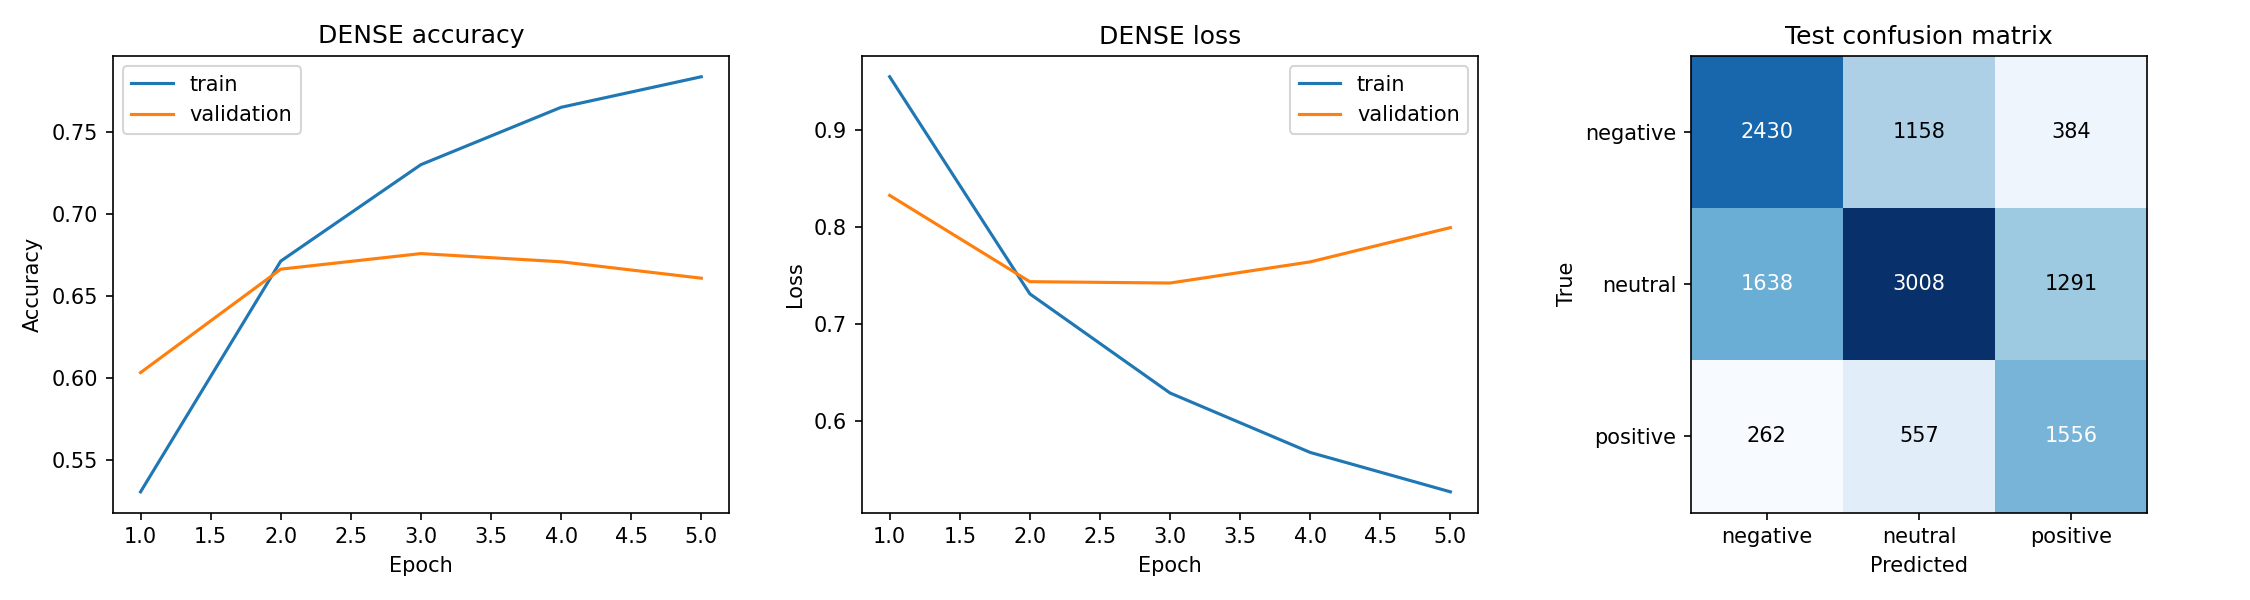

DENSE classification report:
{
  "negative": {
    "precision": 0.5612009237875288,
    "recall": 0.6117824773413897,
    "f1-score": 0.5854011081667068,
    "support": 3972.0
  },
  "neutral": {
    "precision": 0.6368833368621639,
    "recall": 0.5066531918477345,
    "f1-score": 0.5643527204502814,
    "support": 5937.0
  },
  "positive": {
    "precision": 0.48158464871556794,
    "recall": 0.655157894736842,
    "f1-score": 0.5551195148055654,
    "support": 2375.0
  },
  "accuracy": 0.5693585151416477,
  "macro avg": {
    "precision": 0.5598896364550868,
    "recall": 0.5911978546419888,
    "f1-score": 0.5682911144741846,
    "support": 12284.0
  },
  "weighted avg": {
    "precision": 0.5823860290568387,
    "recall": 0.5693585151416477,
    "f1-score": 0.5693735062369503,
    "support": 12284.0
  }
}


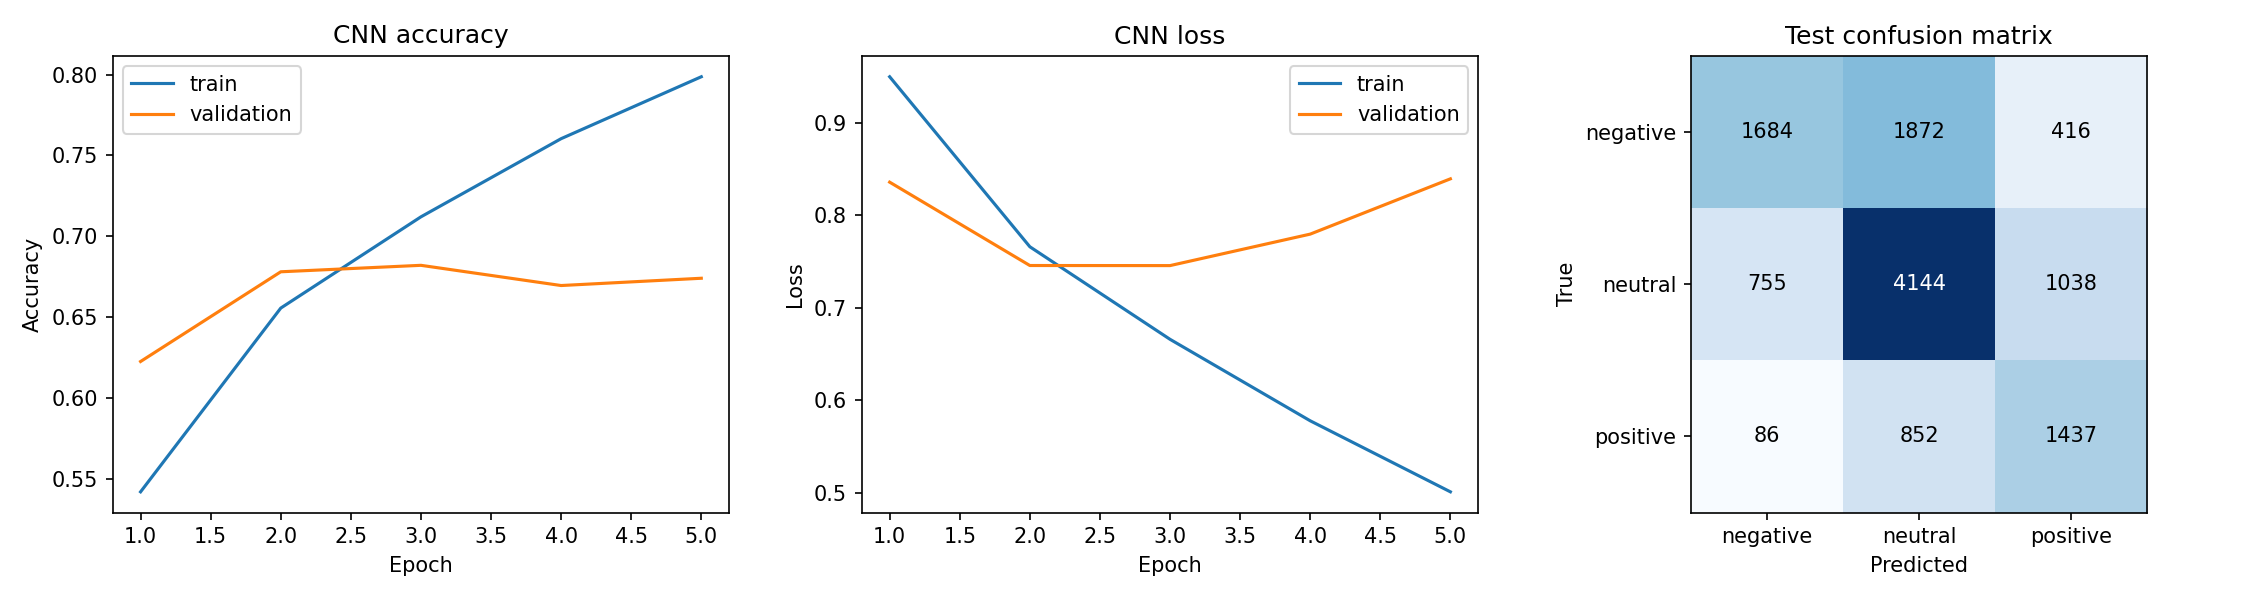

CNN classification report:
{
  "negative": {
    "precision": 0.666930693069307,
    "recall": 0.42396777442094663,
    "f1-score": 0.5183931045097737,
    "support": 3972.0
  },
  "neutral": {
    "precision": 0.6033779848573093,
    "recall": 0.697995620683847,
    "f1-score": 0.6472471690745802,
    "support": 5937.0
  },
  "positive": {
    "precision": 0.49705984088550675,
    "recall": 0.6050526315789474,
    "f1-score": 0.5457652867451576,
    "support": 2375.0
  },
  "accuracy": 0.591419732985998,
  "macro avg": {
    "precision": 0.589122839604041,
    "recall": 0.5756720088945803,
    "f1-score": 0.5704685201098373,
    "support": 12284.0
  },
  "weighted avg": {
    "precision": 0.6033719416372689,
    "recall": 0.591419732985998,
    "f1-score": 0.5859619350316145,
    "support": 12284.0
  }
}


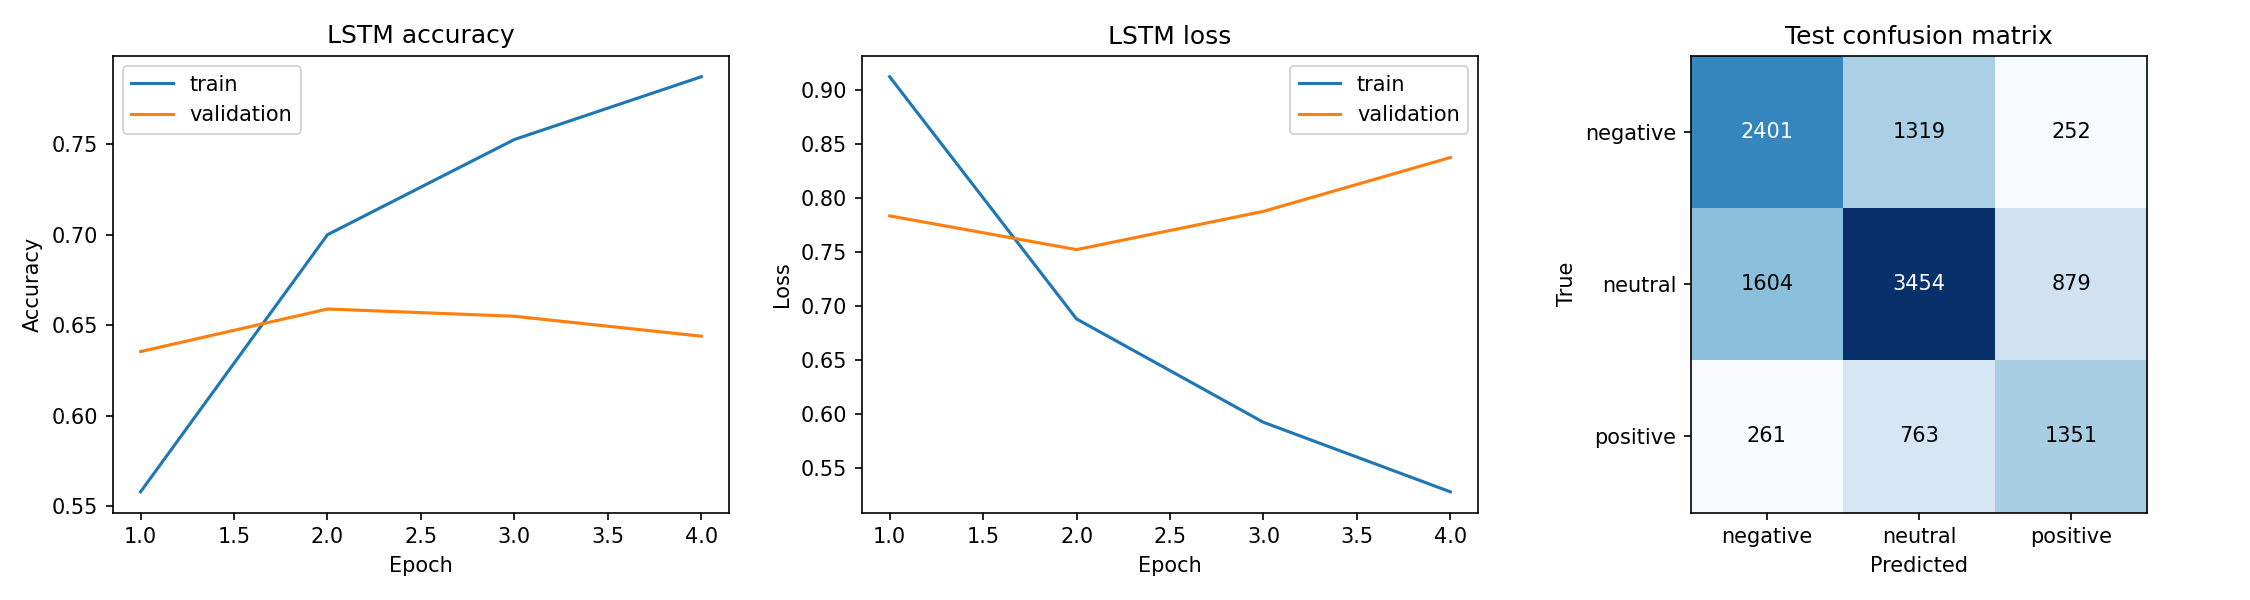

LSTM classification report:
{
  "negative": {
    "precision": 0.5628223159868729,
    "recall": 0.6044813695871097,
    "f1-score": 0.5829084729303229,
    "support": 3972.0
  },
  "neutral": {
    "precision": 0.6239161849710982,
    "recall": 0.5817753073943069,
    "f1-score": 0.6021093000958773,
    "support": 5937.0
  },
  "positive": {
    "precision": 0.5443190975020145,
    "recall": 0.5688421052631579,
    "f1-score": 0.5563104797199918,
    "support": 2375.0
  },
  "accuracy": 0.5866167372191469,
  "macro avg": {
    "precision": 0.5770191994866619,
    "recall": 0.5850329274148582,
    "f1-score": 0.5804427509153973,
    "support": 12284.0
  },
  "weighted avg": {
    "precision": 0.5887722635819403,
    "recall": 0.5866167372191469,
    "f1-score": 0.5870459751289032,
    "support": 12284.0
  }
}


In [4]:
for name in metrics:
    display(Image(filename=str(ARTIFACTS / f'{name}_evaluation.png')))
    print(name.upper(), 'classification report:')
    print(json.dumps(metrics[name]['test']['classification_report'], indent=2))

## Predict with the saved model
Each `.keras` file includes its vocabulary and text vectorizer. The selected model comes from `summary.json`. These are demonstration predictions, not additional evaluation data.

In [5]:
result = subprocess.run([sys.executable, str(ROOT / 'predict.py'),
                         'I really loved this experience!',
                         'This was disappointing and awful.',
                         'The meeting starts at three.'],
                        cwd=ROOT, check=True, capture_output=True, text=True)
print(result.stdout)

[
  {
    "text": "I really loved this experience!",
    "sentiment": "positive",
    "probabilities": {
      "negative": 0.00017952568305190653,
      "neutral": 0.0013612192124128342,
      "positive": 0.9984593391418457
    }
  },
  {
    "text": "This was disappointing and awful.",
    "sentiment": "negative",
    "probabilities": {
      "negative": 0.9935543537139893,
      "neutral": 0.006263618357479572,
      "positive": 0.00018206489039584994
    }
  },
  {
    "text": "The meeting starts at three.",
    "sentiment": "positive",
    "probabilities": {
      "negative": 0.020628314465284348,
      "neutral": 0.3363439738750458,
      "positive": 0.6430277228355408
    }
  }
]



## Limitations
These small networks are CPU-friendly baselines trained from scratch, not pretrained transformer models. Historical English tweets do not represent every language or current social media usage. Basic lowercase/punctuation normalization can lose emoji and hashtag information; sarcasm and domain shift remain difficult. Metrics are from one seeded run and do not establish significance. The revised three-class task is not directly comparable with the original notebook?s positive-versus-everything mapping.